# Models and Simulation

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
np.random.seed(1)

## Deterministic Models

- **Deterministic**: same starting conditions always give the same result
- **Exponential decay**: $N(t) = N_0 \exp(-kt)$
- **Exponential growth**: $N(t) = N_0 \exp(rt)$

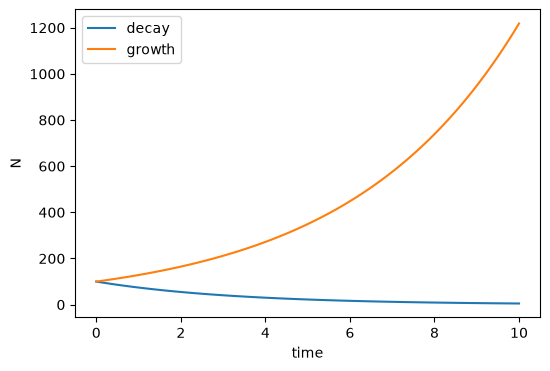

In [22]:
t = np.linspace(0, 10, 100)
N0 = 100
k = 0.3
r = 0.25

decay = N0 * np.exp(-k * t)
growth = N0 * np.exp(r * t)

plt.figure(figsize=(6,4))
plt.plot(t, decay, label='decay')
plt.plot(t, growth, label='growth')
plt.xlabel('time'); plt.ylabel('N'); plt.legend();

Homework: Say you have a given dataset and you want to fit a deterministic exponential growth model to it. How will you do that? (Check the curve fitting code from scipy!)

## 2. Introduction to Random Processes

- **Random process** - outcome is not fixed, involves chance
- **Random walk** - each step moves randomly up or down
- Repeated runs give different paths even from the same start

<Figure size 600x400 with 0 Axes>

Text(0.5, 0, 'step')

Text(0, 0.5, 'position')

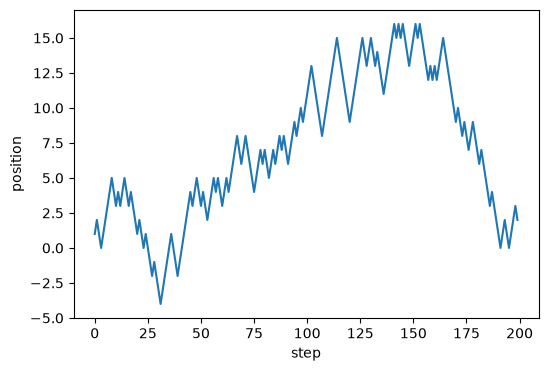

In [23]:
n_steps = 200
steps = np.random.choice([-1, 1], size=n_steps)
walk = np.cumsum(steps)

plt.figure(figsize=(6,4))
plt.plot(walk)
plt.xlabel('step'); plt.ylabel('position')
plt.show()

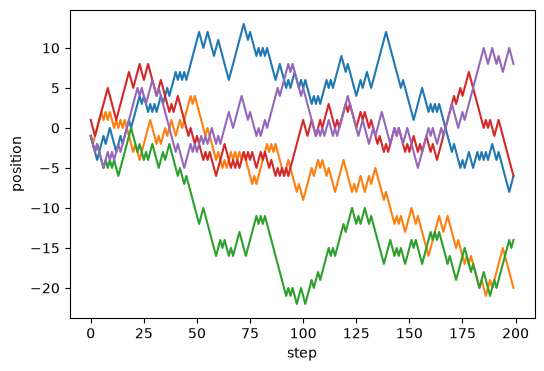

In [24]:
n_walks = 5
walks = np.cumsum(np.random.choice([-1, 1], size=(n_walks, n_steps)), axis=1)

plt.figure(figsize=(6,4))
for w in walks:
    plt.plot(w)
plt.xlabel('step'); plt.ylabel('position');

## Numerical Simulation

- Build the model stochastically
- Useful when systems are random or too complex
- Example: simulate decay using random chance for each atom

<Axes: xlabel='step', ylabel='$N$ remaining'>

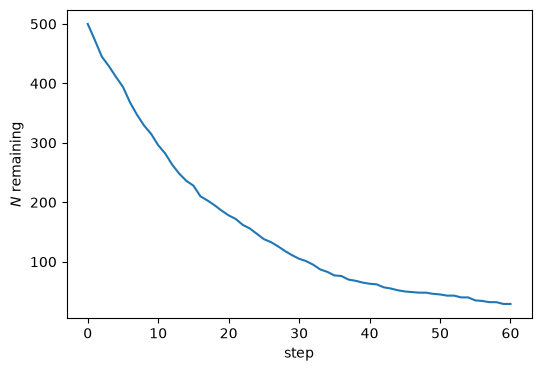

In [25]:
N0 = 500
p_decay = 0.05
steps = 60

n_remaining = [N0]
for _ in range(steps):
    current = n_remaining[-1]
    decays = np.random.binomial(current, p_decay)
    n_remaining.append(current - decays)

sim_decay = pd.Series(n_remaining)
sim_decay.plot(figsize=(6,4), xlabel='step', ylabel='$N$ remaining')

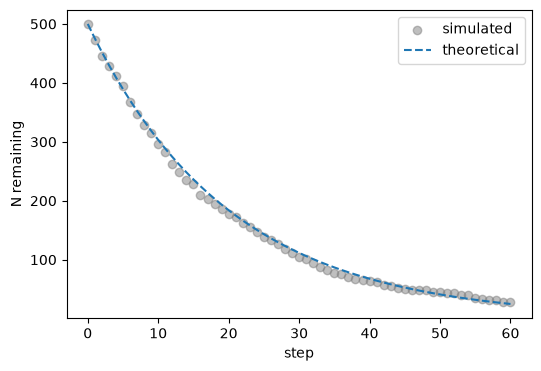

In [26]:
t_theory = np.arange(steps + 1)
theory_decay = N0 * np.exp(-p_decay * t_theory)

plt.figure(figsize=(6,4))
plt.scatter(range(len(sim_decay)), sim_decay, label='simulated', color='gray',alpha=0.5)
plt.plot(theory_decay, label='theoretical', linestyle='--')
plt.xlabel('step'); plt.ylabel('N remaining'); plt.legend();

## Monte Carlo (MC) Methods

MC methods are useful for solving problems that are analytically intractable or computationally complex. Instead of averaging over all states, MC methods sample a subset of phase space to approximate "ensemble averages" with the following steps:

1. Randomly select a new configuration (using a Markov Chain)
2. Accept/reject the configuration based on a chosen strategy.  
3. Compute the physical quantity and update the average.  
4. Repeat the process.  

Figure from: Böttcher, L., & Herrmann, H. J. (2021). Computational Statistical Physics (1st ed.). Cambridge University Press. https://doi.org/10.1017/9781108882316 p. 68

![](MC.png)

### Example: Computation of Integrals

- Monte Carlo integration is especially efficient for high-dimensional problems.
- Given a function $g(x)$ over an interval $[a, b]$, simple sampling approximates the integral as:
$$
\int_a^b g(x){\rm d}x \approx (b - a) \frac{1}{N} \sum_{i=1}^{N} g(x_i)
$$  
where $x_i$ are randomly chosen points. 
- If $g(x)$ is not smooth, importance sampling can improve accuracy by choosing sample points based on a probability density function $p(x)$ for which $g(x)/p(x)$ is smooth. This gives:  
$$
\int_a^b g(x){\rm d}x = \int_a^b \frac{g(x)}{p(x)} p(x){\rm d}x \approx (b - a) \frac{1}{N} \sum_{i=1}^{N} \frac{g(x_i)}{p(x_i)}
$$  
- In essence, $p(x)$ helps to *choose* sampling points according to their importance (e. g., choosing more points close to a singularity). This is know as **importance sampling**.

### Comparison of errors in MC and other methods

- In conventional methods (e.g., trapezoidal rule), the error scales as $\mathcal{O}(N^{-2/d})$.
- The error in MC estimate for $Q = \int_{a_1}^{b_1} {\rm d}x_1 \int_{a_2}^{b_2} {\rm d}x_2 \dots \int_{a_n}^{b_n} {\rm d}x_n\; g(x_1, \dots, x_n)$
decreases with increasing number of sampling points ($N$) as $\mathcal{O}(N^{-1/2})$, independent of dimension.
- MC becomes more efficient than the trapezoidal rule when $d > 4$. (see Böttcher and Hermann, pp. 66–71 if you're interested in derivations)
- Thus, MC methods are preferred for high-dimensional integrals, while conventional methods work well for low-dimensional cases.

## References



- **(For a quick reminder of probability theory)** Grinstead, C. M., & Snell, J. L. (2006). Introduction to Probability. American Mathematical Society. https://math.dartmouth.edu/~prob/prob/prob.pdf
- **(If you want to know *much more* about MC methods from CS perspective.)**: Check CMU's [Keenan Crane's course webpage](https://gi1242.codeberg.page/cmu-math-cs-mcm/)


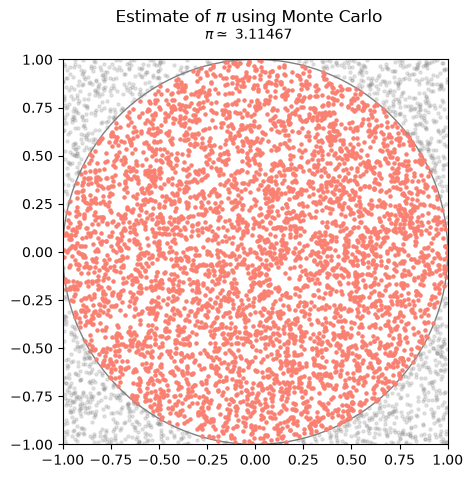

In [27]:
# Compute pi with Monte Carlo (uniform sampling as importance sampling is not required.)

n, step = 5000, 500
frames = n // step
x_in, y_in, x_out, y_out = [], [], [], []

fig, ax = plt.subplots(figsize=(5, 5))
ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_aspect('equal')
# fig.subplots_adjust(top=0.85)
fig.suptitle(r"Estimate of $\pi$ using Monte Carlo")
pi_txt = fig.text(0.5, 0.92, "", ha="center")

ax.add_patch(plt.Circle((0, 0), 1, color='gray', fill=False))
sc_in = ax.scatter([], [], color="salmon", s=5, alpha=1)
sc_out = ax.scatter([], [], color="gray", s=5, alpha=0.2)

def update(_):
    x, y = np.random.uniform(-1, 1, step), np.random.uniform(-1, 1, step)
    inside = x**2 + y**2 <= 1
    x_in.extend(x[inside]), y_in.extend(y[inside])
    x_out.extend(x[~inside]), y_out.extend(y[~inside])
    pi_txt.set_text(rf"$\pi \simeq$ {4 * len(x_in) / (len(x_in) + len(x_out)):.5f}")
    sc_in.set_offsets(np.c_[x_in, y_in])
    sc_out.set_offsets(np.c_[x_out, y_out])
    return sc_in, sc_out, pi_txt

ani = animation.FuncAnimation(fig, update, frames=frames, interval=1, blit=False);
ani.save("monte_carlo_pi.gif", writer="pillow", fps=2);

